# Recruitment Analytics: Random Forest vs Neural Network

This notebook is the **Recruitment Analytics (Machine Learning) module** of JobMatch AI. It predicts how suitable a candidate is (*Highly*, *Moderately* or *Less Suitable*) from 24 attributes, using:

* **Machine learning:** a Random Forest classifier (300 trees, balanced class weights)
* **Deep learning:** a feed-forward neural network built with TensorFlow/Keras

Both models use the same pre-processing and the same stratified 80:20 split, so their results can be compared fairly.

**Dataset:** `data/talent_recruitment.csv`, a synthetic dataset of 12,000 candidates and 26 attributes, produced by `generate_dataset.py`. Run that script first if the file is missing.

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA = Path("data/talent_recruitment.csv")
FIGURES = Path("figures"); FIGURES.mkdir(exist_ok=True)
MODELS = Path("models"); MODELS.mkdir(exist_ok=True)

## 1. Load and inspect the dataset

In [2]:
df = pd.read_csv(DATA)
print("Shape:", df.shape)
df.head()

Shape: (12000, 26)


,Candidate_ID,Gender,Age,Location,Highest_Degree,Specialization,CGPA,Experience_Years,Current_Role,Preferred_Job_Title,...,Problem_Solving_Score,Resume_Score,Job_Applications_Count,Interview_Attempts,Recruiter_Rating,Preferred_Work_Mode,Career_Level,Technical_Skills,Certifications,Target_Category
0,C00001,Female,36,Guangzhou,Bachelor's,Mechanical,6.84,1,Data Analyst,Data Analyst,...,38,46,2,6,2.2,Onsite,Entry,SQL;Excel;Power BI;Python,No Certification,Less Suitable
1,C00002,Female,39,Shanghai,Bachelor's,Computer Science,7.43,16,UI/UX Designer,UI/UX Designer,...,85,87,14,12,1.2,Onsite,Entry,Figma;Prototyping;User Research,Scrum Master,Highly Suitable
2,C00003,Female,40,Shenzhen,Master's,Management,9.68,13,DevOps Engineer,Software Engineer,...,87,46,17,15,4.7,Hybrid,Lead,Python;Java;SQL;Git,Azure Fundamentals,Highly Suitable
3,C00004,Female,29,Nanjing,Bachelor's,Electronics,6.77,9,Product Manager,Product Manager,...,76,97,1,3,1.7,Onsite,Senior,Agile;Jira;Analytics;Roadmapping,No Certification,Highly Suitable
4,C00005,Female,24,Guangzhou,Master's,Management,7.87,9,Sales Executive,Sales Executive,...,77,91,50,3,1.6,Hybrid,Senior,Negotiation;CRM;Communication,No Certification,Highly Suitable


In [3]:
summary = pd.DataFrame({
    "Records x attributes": [f"{df.shape[0]:,} x {df.shape[1]}"],
    "Missing values": [int(df.isna().sum().sum())],
    "Duplicate records": [int(df.duplicated().sum())],
})
summary.T

,0
Records x attributes,"12,000 x 26"
Missing values,0
Duplicate records,0


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,12000.0,37.99,10.06,21.0,29.00,38.00,47.00,55.0
CGPA,12000.0,7.50,1.44,5.0,6.25,7.49,8.76,10.0
Experience_Years,12000.0,9.94,6.02,0.0,5.00,10.00,15.00,20.0
Current_Salary_CNY_K,12000.0,330.41,155.98,60.0,195.20,330.10,464.80,599.9
Expected_Salary_CNY_K,12000.0,420.94,204.74,63.2,246.58,415.45,586.15,896.5
Communication_Score,12000.0,50.50,28.99,1.0,25.00,50.00,76.00,100.0
Leadership_Score,12000.0,50.41,28.84,1.0,25.00,50.00,75.00,100.0
Problem_Solving_Score,12000.0,50.58,28.90,1.0,26.00,51.00,76.00,100.0
Resume_Score,12000.0,50.72,28.86,1.0,26.00,51.00,76.00,100.0
Job_Applications_Count,12000.0,25.53,14.51,1.0,13.00,25.00,38.00,50.0


## 2. Exploratory data analysis

Target_Category
Highly Suitable        34.3 %
Less Suitable          33.3 %
Moderately Suitable    32.4 %
Name: count, dtype: str


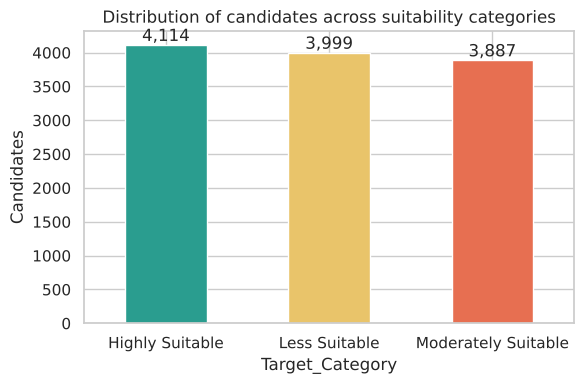

In [5]:
counts = df["Target_Category"].value_counts()
print((counts / len(df) * 100).round(1).astype(str) + " %")
ax = counts.plot(kind="bar", color=["#2a9d8f", "#e9c46a", "#e76f51"], figsize=(6, 4), rot=0)
ax.set_title("Distribution of candidates across suitability categories"); ax.set_ylabel("Candidates")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.savefig(FIGURES / "target_distribution.png", dpi=150); plt.show()

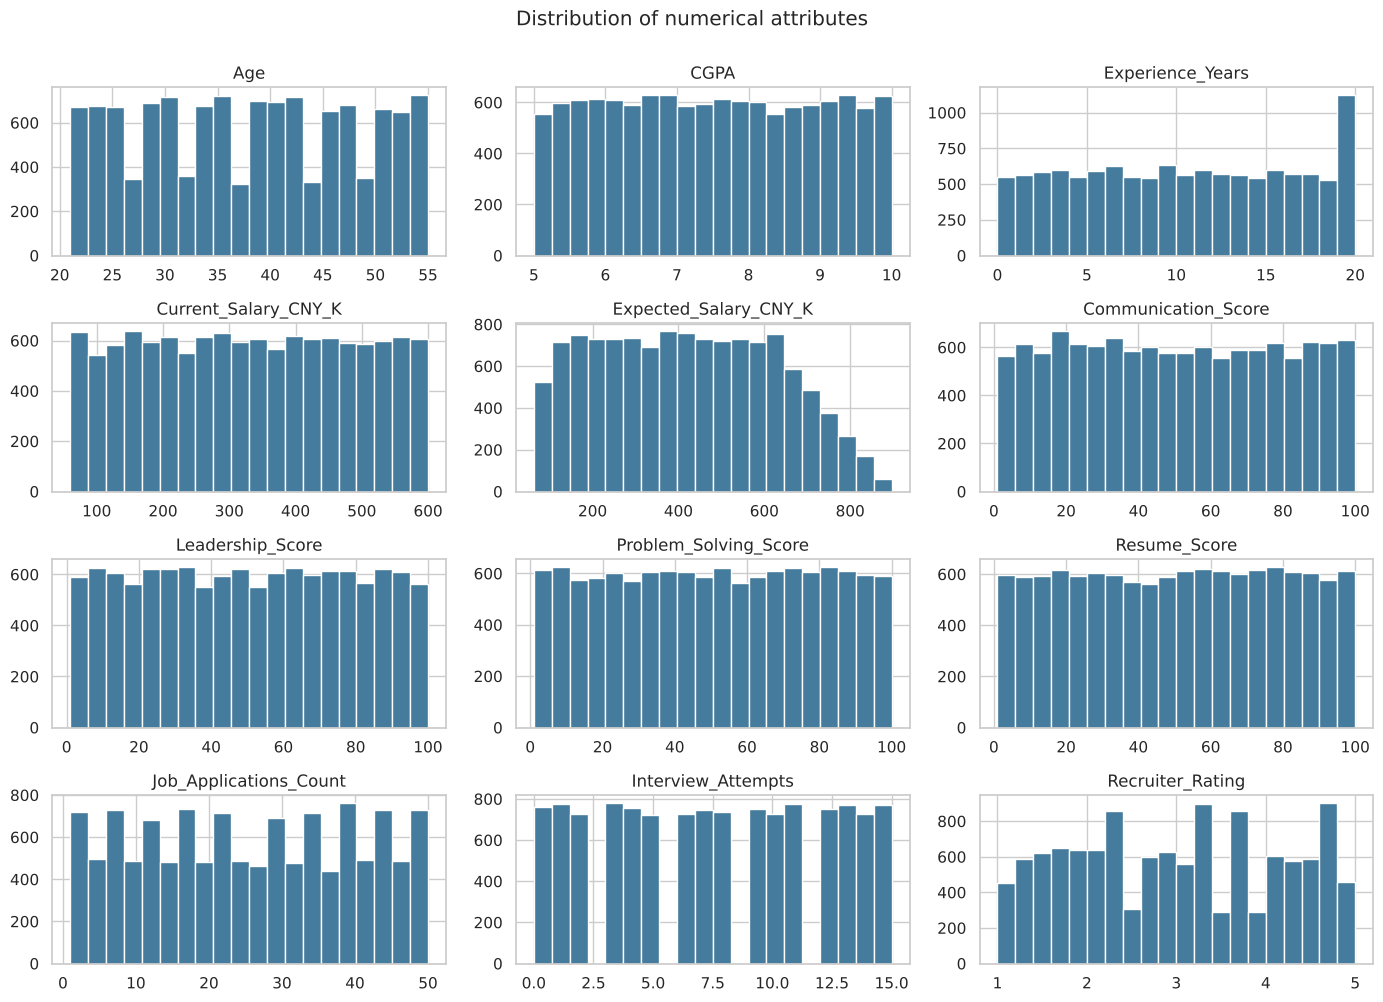

In [6]:
numerical_features = df.select_dtypes(include="number").columns.tolist()
df[numerical_features].hist(bins=20, figsize=(14, 10), color="#457b9d")
plt.suptitle("Distribution of numerical attributes", y=1.0)
plt.tight_layout(); plt.savefig(FIGURES / "numeric_histograms.png", dpi=150); plt.show()

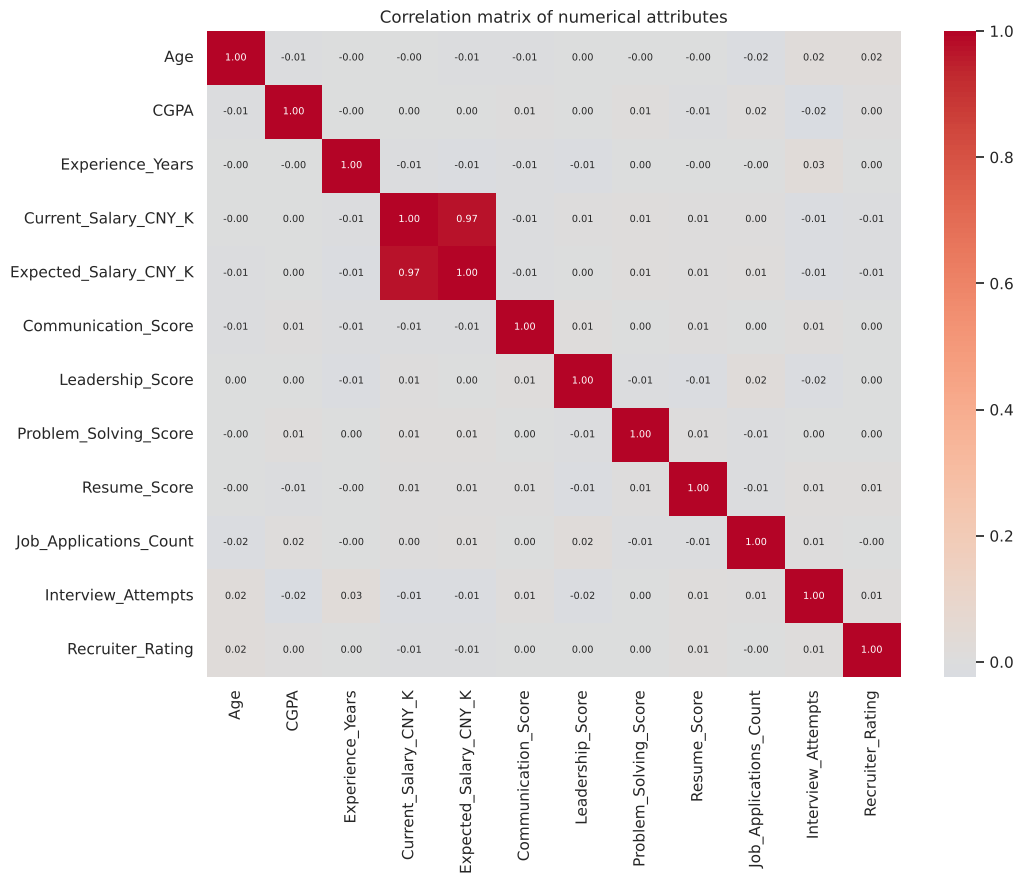

Current vs expected salary r = 0.973


In [7]:
corr = df[numerical_features].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation matrix of numerical attributes")
plt.tight_layout(); plt.savefig(FIGURES / "correlation_matrix.png", dpi=150); plt.show()
print("Current vs expected salary r =", round(corr.loc["Current_Salary_CNY_K", "Expected_Salary_CNY_K"], 3))

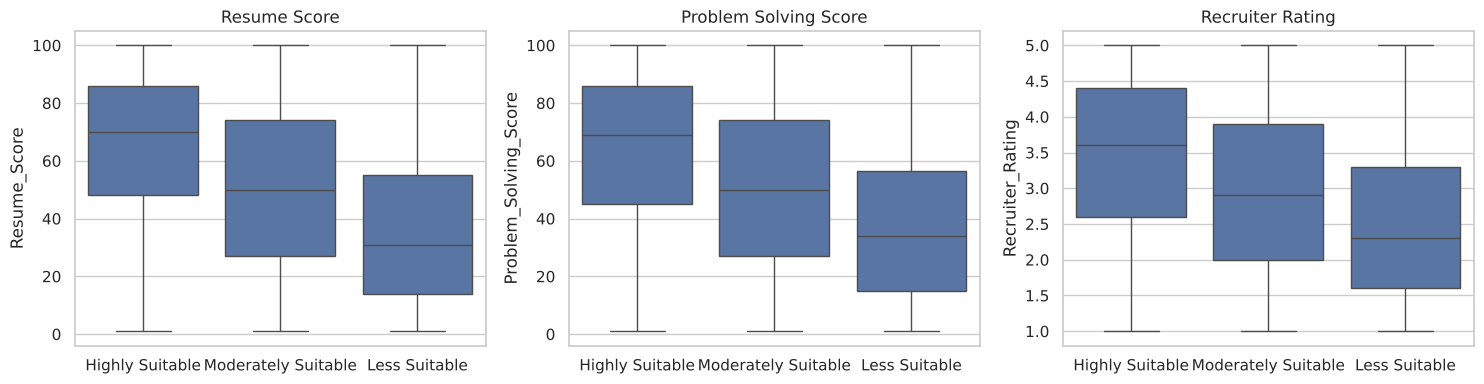

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Resume_Score", "Problem_Solving_Score", "Recruiter_Rating"]):
    sns.boxplot(data=df, x="Target_Category", y=col, ax=ax,
                order=["Highly Suitable", "Moderately Suitable", "Less Suitable"])
    ax.set_title(col.replace("_", " ")); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIGURES / "scores_by_category.png", dpi=150); plt.show()

## 3. Prepare features and target

In [9]:
X = df.drop(columns=["Candidate_ID", "Target_Category"])
y = df["Target_Category"]
numerical_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
print(len(numerical_features), "numerical:", numerical_features)
print(len(categorical_features), "categorical:", categorical_features)

12 numerical: ['Age', 'CGPA', 'Experience_Years', 'Current_Salary_CNY_K', 'Expected_Salary_CNY_K', 'Communication_Score', 'Leadership_Score', 'Problem_Solving_Score', 'Resume_Score', 'Job_Applications_Count', 'Interview_Attempts', 'Recruiter_Rating']
12 categorical: ['Gender', 'Location', 'Highest_Degree', 'Specialization', 'Current_Role', 'Preferred_Job_Title', 'Industry', 'Company_Name', 'Preferred_Work_Mode', 'Career_Level', 'Technical_Skills', 'Certifications']


## 4. Stratified 80:20 train/test split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Training:", X_train.shape, " Testing:", X_test.shape)

Training: (9600, 24)  Testing: (2400, 24)


## 5. Pre-processing pipeline\nMedian imputation and standard scaling for numbers; most-frequent imputation and one-hot encoding for categories.

In [11]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features),
])

## 6. Machine learning: Random Forest

In [12]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE,
                                          n_jobs=-1, class_weight="balanced")),
])
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)
print(f"Random Forest accuracy: {rf_acc:.4f}\n")
print(classification_report(y_test, rf_pred, digits=3))

Random Forest accuracy: 0.6571

                     precision    recall  f1-score   support

    Highly Suitable      0.713     0.762     0.736       823
      Less Suitable      0.719     0.766     0.742       800
Moderately Suitable      0.505     0.434     0.467       777

           accuracy                          0.657      2400
          macro avg      0.645     0.654     0.648      2400
       weighted avg      0.647     0.657     0.651      2400



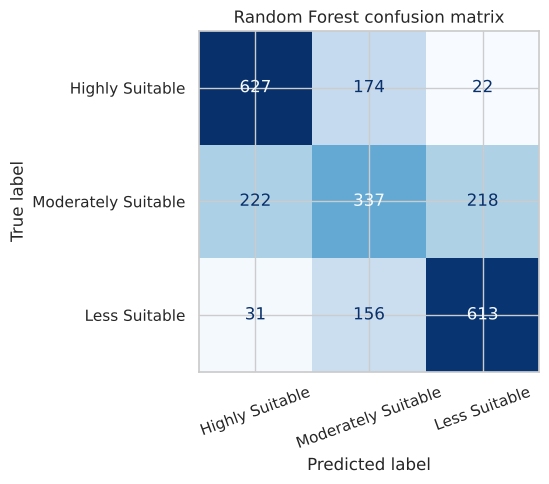

In [13]:
LABELS = ["Highly Suitable", "Moderately Suitable", "Less Suitable"]
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, rf_pred, labels=LABELS), display_labels=LABELS).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=20)
ax.set_title("Random Forest confusion matrix")
plt.tight_layout(); plt.savefig(FIGURES / "rf_confusion_matrix.png", dpi=150); plt.show()

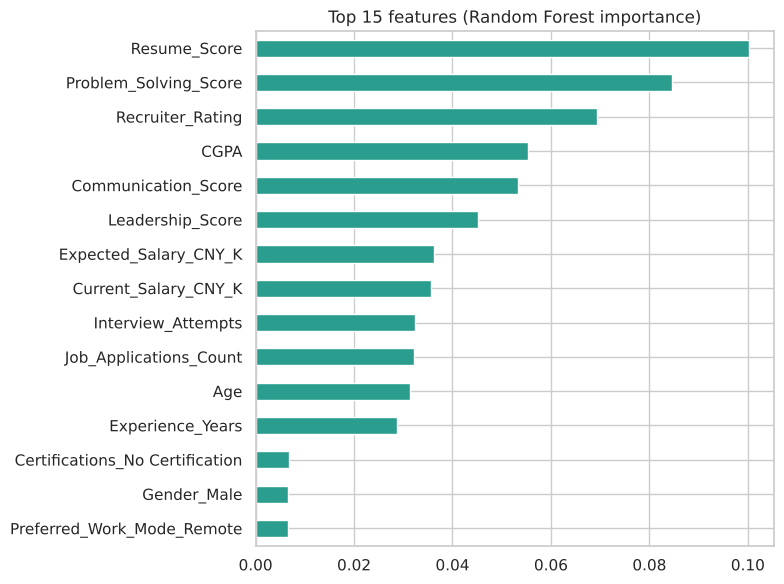

In [14]:
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()
importances = pd.Series(rf_model.named_steps["classifier"].feature_importances_, index=feature_names)
top = importances.sort_values(ascending=False).head(15)
top.index = [n.split("__", 1)[1] for n in top.index]
ax = top.sort_values().plot(kind="barh", figsize=(8, 6), color="#2a9d8f")
ax.set_title("Top 15 features (Random Forest importance)")
plt.tight_layout(); plt.savefig(FIGURES / "rf_feature_importance.png", dpi=150); plt.show()

## 7. Deep learning: neural network (Keras)

A multi-layer perceptron on the same pre-processed features: two hidden layers with batch normalisation and dropout, a softmax output over the three classes, the Adam optimiser and early stopping on a validation split.

In [15]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import keras
from keras import layers

keras.utils.set_random_seed(RANDOM_STATE)
dl_pre = preprocessor.fit(X_train)   # same steps, fitted on training data only
Xtr = dl_pre.transform(X_train).astype("float32")
Xte = dl_pre.transform(X_test).astype("float32")
classes = sorted(y.unique())
ytr = y_train.map({c: i for i, c in enumerate(classes)}).to_numpy()
yte = y_test.map({c: i for i, c in enumerate(classes)}).to_numpy()

nn = keras.Sequential([
    keras.Input(shape=(Xtr.shape[1],)),
    layers.Dense(128, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
    layers.Dense(64, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
    layers.Dense(len(classes), activation="softmax"),
], name="suitability_mlp")
nn.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
nn.summary()

I0000 00:00:1794215198.170618   15468 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794215199.053156   15468 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Model: "suitability_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,603 (100.01 KB)

 Trainable params: 25,219 (98.51 KB)

 Non-trainable params: 384 (1.50 KB)

Epochs run: 18


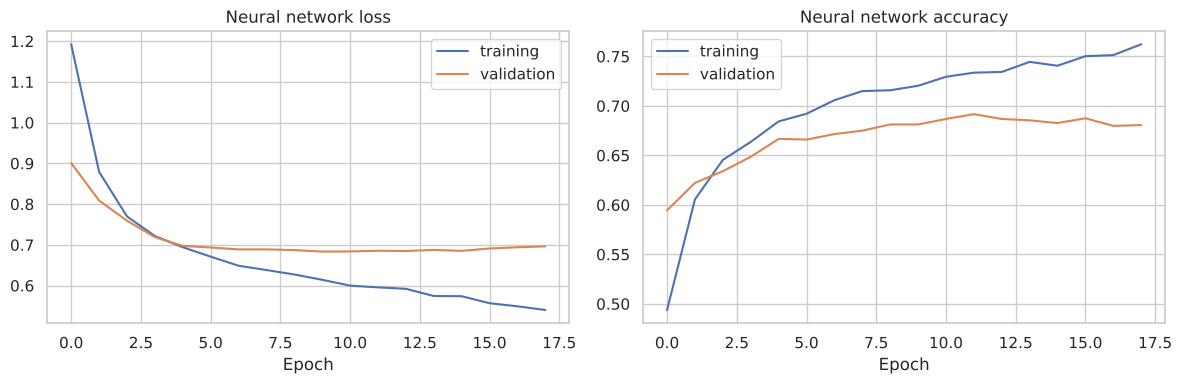

In [16]:
history = nn.fit(Xtr, ytr, validation_split=0.15, epochs=60, batch_size=128, verbose=0,
                 callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
print("Epochs run:", len(history.history["loss"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(history.history[metric], label="training"); ax.plot(history.history["val_" + metric], label="validation")
    ax.set_title(f"Neural network {metric}"); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.savefig(FIGURES / "nn_training_curves.png", dpi=150); plt.show()

Neural network accuracy: 0.6979

                     precision    recall  f1-score   support

    Highly Suitable      0.776     0.761     0.768       823
      Less Suitable      0.785     0.751     0.768       800
Moderately Suitable      0.542     0.577     0.559       777

           accuracy                          0.698      2400
          macro avg      0.701     0.696     0.698      2400
       weighted avg      0.703     0.698     0.700      2400



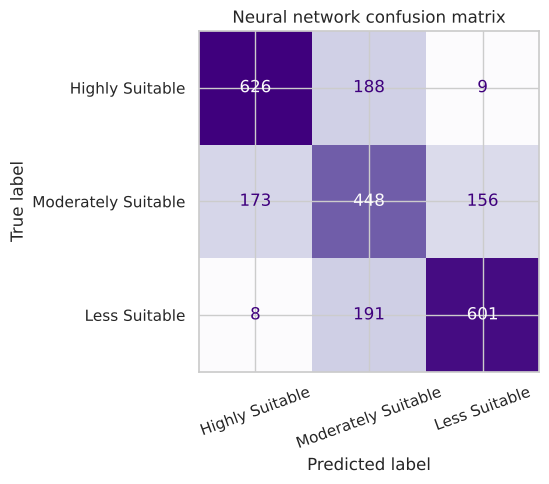

In [17]:
nn_pred = np.array(classes)[nn.predict(Xte, verbose=0).argmax(axis=1)]
nn_acc = accuracy_score(y_test, nn_pred)
print(f"Neural network accuracy: {nn_acc:.4f}\n")
print(classification_report(y_test, nn_pred, digits=3))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, nn_pred, labels=LABELS), display_labels=LABELS).plot(
    ax=ax, cmap="Purples", colorbar=False, xticks_rotation=20)
ax.set_title("Neural network confusion matrix")
plt.tight_layout(); plt.savefig(FIGURES / "nn_confusion_matrix.png", dpi=150); plt.show()

## 8. Comparison of the two models

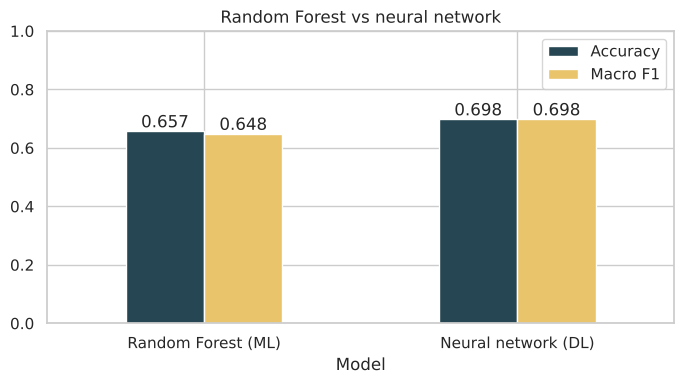

,Model,Accuracy,Macro F1,Weighted F1
0,Random Forest (ML),0.6571,0.6483,0.6508
1,Neural network (DL),0.6979,0.6981,0.7001


In [18]:
comparison = pd.DataFrame({
    "Model": ["Random Forest (ML)", "Neural network (DL)"],
    "Accuracy": [rf_acc, nn_acc],
    "Macro F1": [f1_score(y_test, rf_pred, average="macro"), f1_score(y_test, nn_pred, average="macro")],
    "Weighted F1": [f1_score(y_test, rf_pred, average="weighted"), f1_score(y_test, nn_pred, average="weighted")],
}).round(4)
comparison.to_csv(FIGURES / "model_comparison.csv", index=False)
ax = comparison.set_index("Model")[["Accuracy", "Macro F1"]].plot(kind="bar", rot=0, figsize=(7, 4),
                                                                     color=["#264653", "#e9c46a"])
ax.set_ylim(0, 1); ax.set_title("Random Forest vs neural network")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.savefig(FIGURES / "model_comparison.png", dpi=150); plt.show()
comparison

## 9. Predict suitability for a new candidate

In [19]:
new_candidate = pd.DataFrame([{
    "Gender": "Female", "Age": 27, "Location": "Shanghai", "Highest_Degree": "Master's",
    "Specialization": "Computer Science", "CGPA": 8.7, "Experience_Years": 4,
    "Current_Role": "Data Scientist", "Preferred_Job_Title": "Data Scientist", "Industry": "FinTech",
    "Company_Name": "Company_07", "Current_Salary_CNY_K": 320.0, "Expected_Salary_CNY_K": 380.0,
    "Communication_Score": 82, "Leadership_Score": 64, "Problem_Solving_Score": 88, "Resume_Score": 85,
    "Job_Applications_Count": 12, "Interview_Attempts": 3, "Recruiter_Rating": 4.3,
    "Preferred_Work_Mode": "Hybrid", "Career_Level": "Mid",
    "Technical_Skills": "Python;Machine Learning;Deep Learning;SQL", "Certifications": "Google Data Analytics",
}])
rf_probs = pd.Series(rf_model.predict_proba(new_candidate)[0], index=rf_model.classes_)
nn_probs = pd.Series(nn.predict(dl_pre.transform(new_candidate).astype("float32"), verbose=0)[0], index=classes)
pd.DataFrame({"Random Forest": rf_probs, "Neural network": nn_probs}).round(3)

,Random Forest,Neural network
Highly Suitable,0.87,0.999
Less Suitable,0.04,0.000
Moderately Suitable,0.09,0.001


## 10. Rule-based job matching\nA transparent check of whether a candidate meets a job's basic requirements.

In [20]:
DEGREE_RANK = {"High School": 0, "Diploma": 1, "Bachelor's": 2, "Master's": 3, "PhD": 4}

def job_match(candidate, job):
    checks = {
        "experience": candidate["Experience_Years"] >= job["min_experience"],
        "degree": DEGREE_RANK[candidate["Highest_Degree"]] >= DEGREE_RANK[job["min_degree"]],
        "industry": candidate["Industry"] in job["industries"],
        "job_title": candidate["Preferred_Job_Title"] == job["title"],
        "work_mode": candidate["Preferred_Work_Mode"] in job["work_modes"],
    }
    return round(sum(checks.values()) / len(checks) * 100), checks

job = {"title": "Data Scientist", "min_experience": 3, "min_degree": "Bachelor's",
       "industries": ["FinTech", "IT Services"], "work_modes": ["Hybrid", "Remote"]}
job_match(new_candidate.iloc[0], job)

(100,
 {'experience': np.True_,
  'degree': True,
  'industry': True,
  'job_title': True,
  'work_mode': True})

## 11. Save the trained models

In [21]:
joblib.dump(rf_model, MODELS / "random_forest_pipeline.joblib", compress=3)
nn.save(MODELS / "suitability_nn.keras")
joblib.dump({"preprocessor": dl_pre, "classes": classes}, MODELS / "suitability_nn_preprocessor.joblib", compress=3)
json.dump(comparison.to_dict(orient="records"), open(MODELS / "model_comparison.json", "w"), indent=2)
print("Saved:", sorted(p.name for p in MODELS.iterdir()))

Saved: ['model_comparison.json', 'random_forest_pipeline.joblib', 'suitability_nn.keras', 'suitability_nn_preprocessor.joblib']


## 12. Findings

* The dataset is complete and clean (no missing values, no duplicates), and the three classes are nearly balanced, so accuracy is a meaningful measure.
* Numerical attributes are almost independent of each other, except current and expected salary, which are strongly correlated.
* Assessment scores (resume, problem solving), recruiter rating and CGPA are the most important features, which matches how suitability was defined.
* Both models do far better than the one-in-three chance level. The neural network scores a few points higher on accuracy and F1 here. Suitability mostly comes from a weighted combination of the scores, and a neural network models that kind of smooth combination directly, while a Random Forest approximates it with many step-shaped splits.
* The Random Forest remains useful because it is easier to explain: its feature importances show *why* candidates are rated as they are.
* Both models find *Moderately Suitable* the hardest class, because it sits between the other two and the classes overlap.
* Because the data is synthetic, these results demonstrate the method rather than real-world hiring accuracy.